# Balance Limits: Regional Limits and CO<sub>2</sub> Budgets

The basic tutorial capped the CO<sub>2</sub> emissions of the whole system in every investment period with a **balance limit**. Balance limits can do more. This notebook shows two further uses:

| Topic | Parameters |
|---|---|
| A limit for one region, here on the electricity imports of the south | regional columns in `balanceLimit`, `balanceLimitID` on a transmission |
| One CO<sub>2</sub> budget for all investment periods together | `pathwayBalanceLimit`, `pathwayBalanceLimitID` |

## 1. How balance limits work

A balance limit adds up the yearly operation of all components that refer to its ID and compares the sum with a value. Sources, sinks and transmissions can refer to a balance limit, each to at most one, with `balanceLimitID`. Their operation counts with a sign:

- **Sources** count **positive**: they bring the commodity into the system.
- **Sinks** count **negative**: they take it out.
- **Transmissions** count **positive** in the region they deliver to and **negative** in the region they come from, so they describe the imports of a region.

The limits themselves are a `pd.DataFrame` given as `balanceLimit` to the `EnergySystemModel`, with one row per ID:

- a column `"Total"` for a limit on the whole system, and/or one column per region for regional limits (regions without a limit get `None`),
- a column `"lowerBound"`: `False` (the default) means *the sum must be at most the value*, `True` means *at least the value*.

A dictionary with one such `DataFrame` per investment period gives limits that change over time, as for the CO<sub>2</sub> limit of the basic tutorial. There, the sink "CO2 to environment" counts negative, so the limit of 90 million tonnes is written as *at least −90*.

In [1]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd

import fine as fn
from tutorialHelpers import (
    CO2_LIMIT_PER_PERIOD,
    COLORS,
    buildBasicTutorialModel,
    plotCapacityAndGeneration,
)

warnings.filterwarnings("ignore")  # keeps the output of this tutorial readable

## 2. A regional limit on imports

In the basic tutorial, the south imports a lot of wind power from the north. Suppose the south wants to depend less on the north: its **net imports**, i.e. its imports minus its exports, may be at most **30 TWh per year**.

The limit only applies to the south, so its `DataFrame` has a column `"south"` and no column for the north or the total. Columns that are not given are treated as having no limit. The function `buildBasicTutorialModel` from `tutorialHelpers.py` adds this row to the CO<sub>2</sub> limit of every investment period:

In [2]:
importLimit = pd.DataFrame(
    index=["Imports of the south"],
    columns=["south", "lowerBound"],
    data=[[30000, False]],  # GWh per year, at most
)
importLimit

,south,lowerBound
Imports of the south,30000,False


The AC cables join the limit with `balanceLimitID`. What they deliver to the south counts positive, what they take from the south negative:

In [3]:
esM = buildBasicTutorialModel(balanceLimit=importLimit)
esM.updateComponent("AC cables", {"balanceLimitID": "Imports of the south"})

esM.aggregateTemporally(n_clusters=8, segments=None)
esM.optimize(timeSeriesAggregation=True)

Set parameter OutputFlag to value 1


Set parameter Threads to value 3


Set parameter LogFile to value ""


Set parameter QCPDual to value 1


Gurobi Optimizer version 13.0.1 build v13.0.1rc0 (win64 - Windows 11+.0 (26300.2))


CPU model: Intel(R) Core(TM) Ultra 7 255U, instruction set [SSE2|AVX|AVX2]


... (74 outputs left out)

Solved with barrier


    2536    5.9873277e+05   0.000000e+00   0.000000e+00      1s


Solved in 2536 iterations and 0.70 seconds (0.86 work units)


Optimal objective  5.987327686e+05


The yearly flows on the AC cables in both directions. The electricity sent from the north loses 3.6 % on the way, so the south receives a bit less than the north sends; the balance limit counts what arrives:

In [4]:
lossesOnTheWay = 0.0001 * 357  # losses per km times the distance

flows = {}
for year in esM.investmentPeriodNames:
    summary = esM.getOptimizationSummary("TransmissionModel", outputLevel=1, ip=year)
    operation = summary.loc[("AC cables", "operation")].droplevel("Unit")
    sent = operation.loc["north", "south"] / 1000  # TWh
    returned = operation.loc["south", "north"] / 1000
    flows[year] = {
        "north to south [TWh]": sent,
        "south to north [TWh]": returned,
        "net imports of the south [TWh]": sent * (1 - lossesOnTheWay) - returned,
    }
pd.DataFrame(flows).astype(float).round(1)

,2020,2030,2040
north to south [TWh],20.3,61.7,61.7
south to north [TWh],14.8,29.5,29.5
net imports of the south [TWh],4.8,30.0,30.0


The limit is binding in 2030 and 2040: the net imports of the south are exactly 30 TWh. In the basic tutorial, they were about 85 TWh in 2030 and 64 TWh in 2040. The south reacts in two ways:

- In **2030**, it produces more electricity itself: it builds wind turbines already in 2030 (about 23 GW, none in the basic tutorial) and runs its gas power plants more.
- In **2040**, it keeps almost the capacities of the basic tutorial, but sends much more electricity back to the north (about 30 TWh instead of 1 TWh). Since the limit counts *net* imports, these exports allow the same amount of additional imports in other hours.

The second reaction shows that a balance limit only limits the yearly sum: it says nothing about single hours.

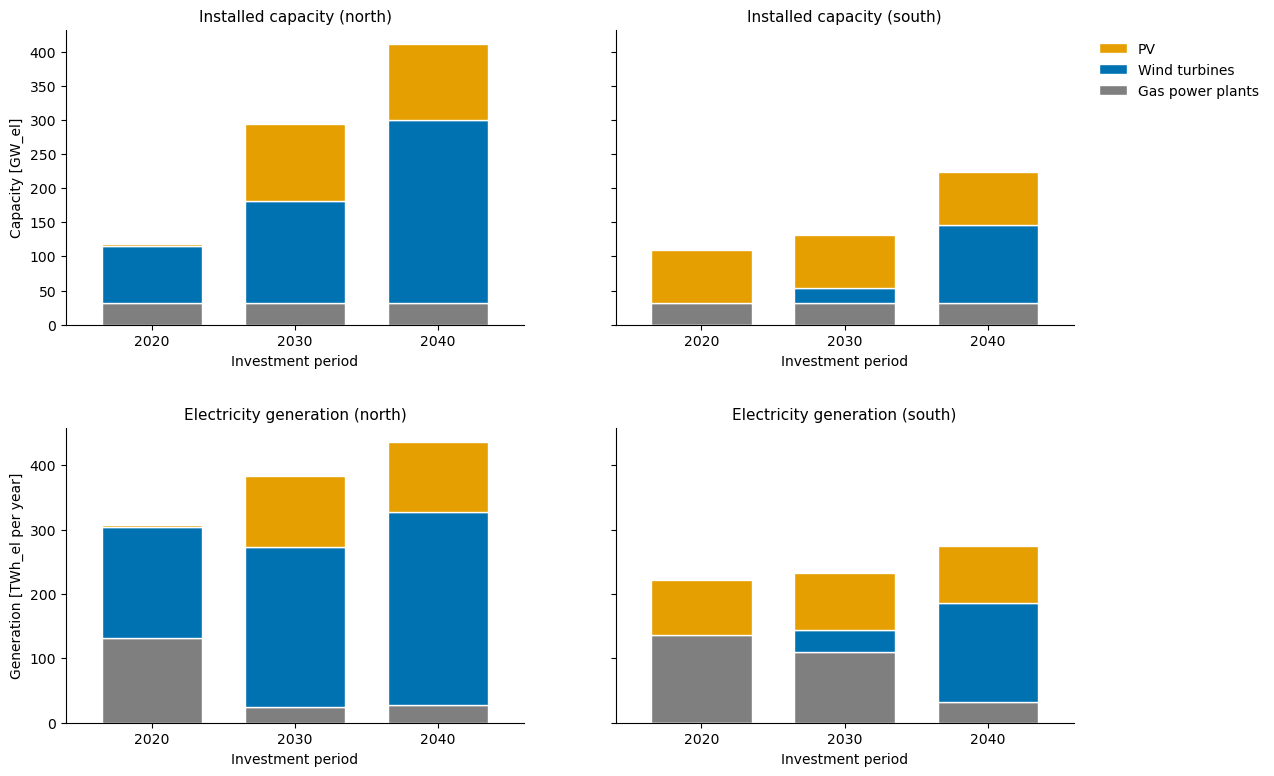

In [5]:
capacity, generation = plotCapacityAndGeneration(
    esM, ["Gas power plants", "Wind turbines", "PV"], byRegion=True
)

## 3. A CO<sub>2</sub> budget for the whole pathway

The CO<sub>2</sub> limit of the basic tutorial fixes the emissions of every investment period. Climate targets are often formulated differently: as a **budget** of emissions for a whole period of time. How the budget is spread over the years is left open.

This is what **`pathwayBalanceLimit`** describes. It has the same format as `balanceLimit`, but without investment periods, and components join it with **`pathwayBalanceLimitID`**. It adds up the yearly balances of all investment periods, each multiplied by the number of years the period stands for (`investmentPeriodInterval`, here 10 years). Our budget is the sum of the yearly limits of the basic tutorial over the 30 years from 2020 to 2049:

In [6]:
co2Budget = 10 * sum(CO2_LIMIT_PER_PERIOD.values())  # million tonnes
co2Budget

1550

We build the model without the yearly CO<sub>2</sub> limit and add a sink for the CO<sub>2</sub> that refers to the budget:

In [7]:
pathwayBalanceLimit = pd.DataFrame(
    index=["CO2 budget"],
    columns=["Total", "lowerBound"],
    data=[[-co2Budget, True]],  # at most co2Budget may leave the system
)

esM = buildBasicTutorialModel(
    co2LimitPerPeriod=None, pathwayBalanceLimit=pathwayBalanceLimit
)
esM.add(
    fn.Sink(
        esM=esM,
        name="CO2 to environment",
        commodity="CO2",
        hasCapacityVariable=False,
        pathwayBalanceLimitID="CO2 budget",
    )
)

esM.aggregateTemporally(n_clusters=8, segments=None)
esM.optimize(timeSeriesAggregation=True)

Set parameter OutputFlag to value 1


Set parameter Threads to value 3


Set parameter LogFile to value ""


Set parameter QCPDual to value 1


Gurobi Optimizer version 13.0.1 build v13.0.1rc0 (win64 - Windows 11+.0 (26300.2))


CPU model: Intel(R) Core(TM) Ultra 7 255U, instruction set [SSE2|AVX|AVX2]


... (72 outputs left out)

Solved with barrier


    3269    5.9653921e+05   0.000000e+00   0.000000e+00      1s


Solved in 3269 iterations and 0.70 seconds (0.89 work units)


Optimal objective  5.965392064e+05


In [8]:
emissions = pd.DataFrame(
    {
        "Yearly limits (basic tutorial) [Mt]": CO2_LIMIT_PER_PERIOD,
        "Budget [Mt]": {
            year: esM.getOptimizationSummary("SourceSinkModel", outputLevel=1, ip=year)
            .loc[("CO2 to environment", "operation")]
            .iloc[0]
            .sum()
            for year in esM.investmentPeriodNames
        },
    }
)
emissions.round(1)

,Yearly limits (basic tutorial) [Mt],Budget [Mt]
2020,90,91.0
2030,45,42.6
2040,20,21.4


<Axes: xlabel='Investment period', ylabel='CO$_2$ emissions [Mt per year]'>

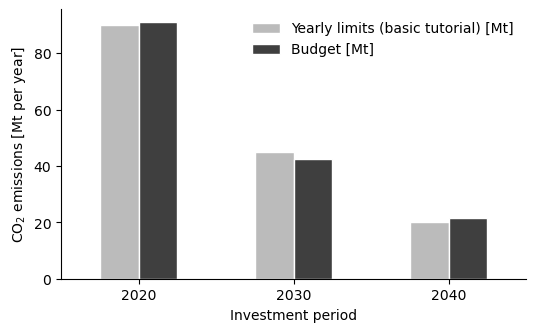

In [9]:
fig, ax = plt.subplots(figsize=(6, 3.5))
emissions.plot.bar(
    ax=ax,
    color=["#BBBBBB", COLORS["CO2 to environment"]],
    edgecolor="white",
    rot=0,
    xlabel="Investment period",
    ylabel="CO$_2$ emissions [Mt per year]",
)

With the budget, the model emits a little more in 2020 and 2040 and less in 2030; over the 30 years, it uses exactly the budget. The total cost falls slightly:

In [10]:
f"Total cost with the budget: {esM.objectiveValue / 1000:.1f} billion Euro (basic tutorial: 597.4)"

'Total cost with the budget: 596.5 billion Euro (basic tutorial: 597.4)'

A budget can never be more expensive than the yearly limits of the basic tutorial: their emissions also fit into the budget, so the optimization could always choose them. Here, the freedom to shift emissions between the periods is worth less than 1 billion Euro.

## Things to try

- Add a minimum production of renewable electricity: give wind turbines and PV the same `balanceLimitID` and a row with `lowerBound=True`, e.g. at least 400 TWh per year from 2030 on.
- Give each region its own CO<sub>2</sub> limit instead of one for the whole system, e.g. 40 million tonnes in the north and 5 in the south in 2040.
- Halve the CO<sub>2</sub> budget. How does the model spread the emissions now?

The next notebook, [Investment Periods](42_investment_periods.ipynb), explains how FINE handles the investment periods of a pathway and how it computes the total cost.